# 01 · Data audit and feature set (Min16 robust pipeline)

**Why this notebook exists.** The previous pipeline (`../Train_3SubModels.ipynb`)
reached test AUC 0.995. However, a classifier that sees *only which cells are
blank* (no values at all) reached test AUC 0.991 on the same data. So the model
mostly learned the data-collection pattern, not the disease:

* PD-only visits (V01, V03, V05, V07, V09, V11) are almost completely empty.
  2,154 PD training rows have no clinical answers at all, and no healthy row does.
* Patients with PATNO ≥ 10000 come from later PD-only PPMI cohorts. They have
  no healthy controls, and several instruments were not collected for them
  (e.g. Thermoregulatory / Urinary_SCOPA in about 10% of their visits,
  versus 93% of original-cohort visits).

How it is fixed while **keeping every clinical feature**:

1. **Visit inclusion:** only visits with **≥ 16 of the 30** items answered
   (`Sparse_Matrix_Min50_*`), for training *and* testing.
2. **Feature set:** all 30 items (handedness was removed from the data in `Make_Datasets`; it has no
   clinical link to PD) = **30 clinical features + age + sex**.
3. **Missingness harmonisation (training rows only):** for each feature, observed
   values are randomly blanked in the class that records it more often, until PD and
   healthy have the same recording rate. This is done inside every CV training fold
   and for the final models (`min16_lib.harmonize_missingness`). **The test set is never modified.**
   A **row floor** keeps every harmonised training row at >= 16 answered features, so the
   training rows still satisfy the visit-inclusion rule of point 1.
4. **Negative-control audit:** a model trained on the blank pattern alone. On the
   harmonised training data its AUC should be close to 0.5.

The coverage table flags low or differential coverage. These flags are **reported only**;
no feature is dropped because of them.

In [ ]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

BASE_DIR = os.getcwd()   # run from the repository root
OUT_DIR  = BASE_DIR
AUD_DIR  = os.path.join(OUT_DIR, "results", "00_audit")
os.makedirs(AUD_DIR, exist_ok=True)

TRAIN_ANY = os.path.join(BASE_DIR, "Train", "Sparse_Matrix_AnyInput_Train.csv")
TEST_ANY  = os.path.join(BASE_DIR, "Test",  "Sparse_Matrix_AnyInput_Test.csv")
TRAIN_50  = os.path.join(BASE_DIR, "Train", "Sparse_Matrix_Min50_Train.csv")
TEST_50   = os.path.join(BASE_DIR, "Test",  "Sparse_Matrix_Min50_Test.csv")

ID_COLS        = ["PATNO", "EVENT_ID", "APPRDX", "Age", "Sex"]
MIN_ANSWERED   = 16      # visit inclusion: >= 16 of 30 clinical items
MIN_COVERAGE   = 0.20    # flag only: observed in < 20% of training visits
MAX_COV_GAP    = 0.05    # flag only: |PD coverage - HC coverage| >= 5 pp
NEW_COHORT_MIN = 10000   # PATNO >= 10000 = later PD-only PPMI cohorts
RANDOM_STATE   = 42
# A-priori exclusions (decided on clinical grounds, not on data):
#   Hand - handedness has no established link to PD; its PD/HC difference in PPMI
#          reflects cohort composition, not disease.
A_PRIORI_EXCLUDE = {"Hand": "a-priori: handedness, no clinical rationale"}

## 1. Cohort composition

In [ ]:
tr_any, te_any = pd.read_csv(TRAIN_ANY), pd.read_csv(TEST_ANY)
tr, te         = pd.read_csv(TRAIN_50),  pd.read_csv(TEST_50)
CLIN = [c for c in tr.columns if c not in ID_COLS]
print(f"{len(CLIN)} clinical columns")

# Confirm the Min50 files really follow the >= 16 answered rule
for name, d in [("train", tr), ("test", te)]:
    n_ans = d[CLIN].notna().sum(axis=1)
    assert (n_ans >= MIN_ANSWERED).all(), f"{name}: rows with < {MIN_ANSWERED} answered"
    print(f"{name}: every visit has >= {MIN_ANSWERED} answered (min = {n_ans.min()})")

def composition(d, name):
    p = d.drop_duplicates("PATNO")
    coh = np.where(p.PATNO >= NEW_COHORT_MIN, "PATNO>=10000 (PD-only cohorts)", "PATNO<10000 (original)")
    t = pd.crosstab(coh, p.APPRDX.map({1: "PD", 2: "Healthy"}))
    return t.reindex(columns=["PD", "Healthy"], fill_value=0).add_prefix(f"{name} ")

comp = pd.concat([composition(tr_any, "AnyInput-train"), composition(tr, "Min16-train"),
                  composition(te, "Min16-test")], axis=1).fillna(0).astype(int)
display(comp)
comp.to_csv(os.path.join(AUD_DIR, "cohort_composition.csv"))

30 clinical columns
train: every visit has >= 16 answered (min = 16)
test: every visit has >= 16 answered (min = 16)


## 2. Where the missingness comes from
Share of visits per feature where the value is recorded, split by class (Min16 training data).

In [ ]:
cov_cls = tr[CLIN].notna().groupby(tr.APPRDX.map({1: "PD", 2: "Healthy"})).mean().T
cov_cls["overall"] = tr[CLIN].notna().mean()
cov_cls["gap_pp"]  = (cov_cls["PD"] - cov_cls["Healthy"]).abs() * 100
coh = np.where(tr.PATNO >= NEW_COHORT_MIN, "PD new cohort", "orig")
cov_coh = tr[CLIN].notna().groupby([coh, tr.APPRDX]).mean().T
cov_coh.columns = ["PD new cohort", "PD original", "Healthy original"]
cov = cov_cls.join(cov_coh)

# Every feature is kept except the a-priori exclusion. Coverage problems are only flagged:
# differential coverage is removed by harmonisation in training, low coverage means mostly imputed.
cov["selected"] = ~cov.index.isin(list(A_PRIORI_EXCLUDE))
cov["flag"] = np.select(
    [cov.index.isin(list(A_PRIORI_EXCLUDE)), cov["gap_pp"] >= MAX_COV_GAP * 100,
     cov["overall"] < MIN_COVERAGE],
    [cov.index.map(A_PRIORI_EXCLUDE).fillna(""),
     f"differential coverage (>= {MAX_COV_GAP*100:.0f} pp): equalised by harmonisation",
     f"low coverage (< {MIN_COVERAGE:.0%}): kept, mostly imputed"], "")
cov = cov.sort_values(["selected", "overall"], ascending=[False, False])
display(cov.round(3))
cov.to_csv(os.path.join(AUD_DIR, "feature_coverage_and_selection.csv"))

FEATURES = cov.index[cov["selected"]].tolist()
print(f"\nUsing {len(FEATURES)} / {len(CLIN)} clinical features:\n  " + ", ".join(FEATURES))
print("\nFlags (reported, not used to drop):\n"
      + cov.loc[cov.flag != "", ["overall", "gap_pp", "flag"]].round(3).to_string())


Using 30 / 30 clinical features:
  REM_AwakeDreamRecall, REM_AwakeDisturbance, REM_DreamActivity, REM_MotorBehavior, Pupillomotor, Gastrointestinal, Depression_GDS, Impulsive, State_Anxiety, Epworth, Semantic, Hopkins_Delay, Symbol_Digit_Modalities, Letter_Number_Sequencing, Hopkins_Recognition, Benton, Cardiovascular, Montreal_Cognitive, Cognitive_Category, Thermoregulatory, Urinary_SCOPA, Education, Smell, Impulsive_Others, Lexical_Fluency, Modified_Boston, Trail_Making_A, Trail_Making_B, Trait_Anxiety, Clock_Drawing

Flags (reported, not used to drop):
                    overall  gap_pp                                                         flag
Cardiovascular        0.926   9.823  differential coverage (>= 5 pp): equalised by harmonisation
Cognitive_Category    0.853   9.280  differential coverage (>= 5 pp): equalised by harmonisation
Thermoregulatory      0.770  22.704  differential coverage (>= 5 pp): equalised by harmonisation
Urinary_SCOPA         0.767  23.205  differential

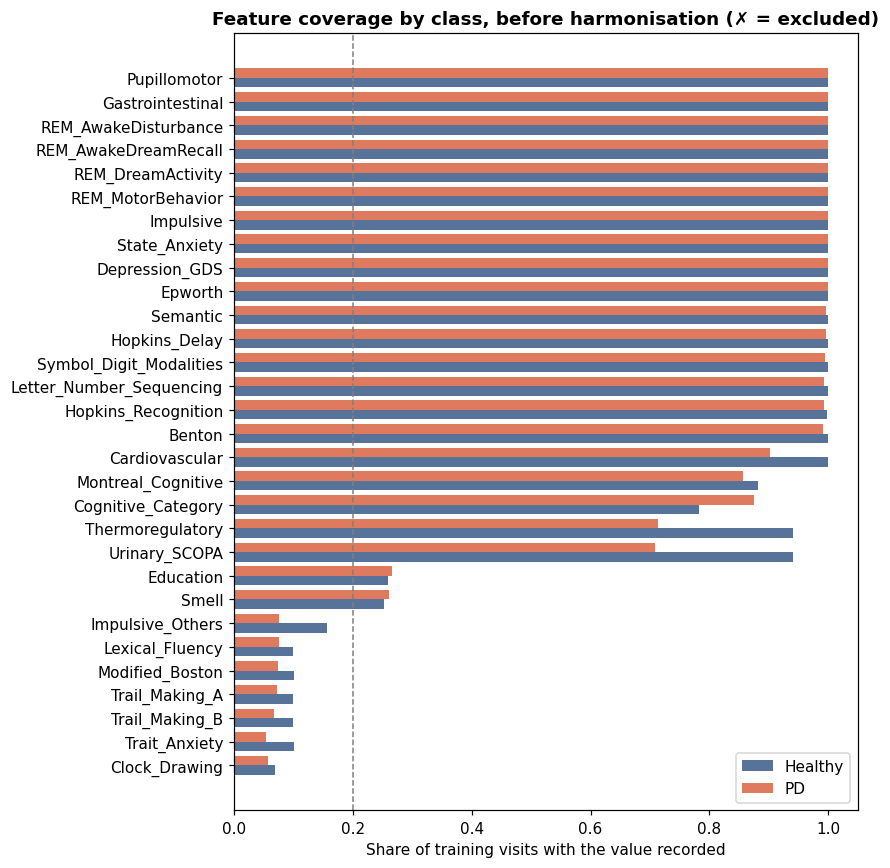

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))
c = cov.sort_values("overall")
y = np.arange(len(c))
ax.barh(y - 0.2, c["Healthy"], 0.4, label="Healthy", color="#577399")
ax.barh(y + 0.2, c["PD"], 0.4, label="PD", color="#E07A5F")
ax.set_yticks(y); ax.set_yticklabels([f"{i}{'' if s else '  ✗'}" for i, s in zip(c.index, c.selected)])
ax.axvline(MIN_COVERAGE, ls="--", c="grey", lw=1)
ax.set_xlabel("Share of training visits with the value recorded")
ax.set_title("Feature coverage by class, before harmonisation (✗ = excluded)", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(os.path.join(AUD_DIR, "feature_coverage.png"), bbox_inches="tight")
fig.savefig(os.path.join(AUD_DIR, "feature_coverage.svg"), bbox_inches="tight")
plt.show()

## 3. Negative-control audit: can the *missingness pattern alone* predict the label?

Each patient is described only by the share of their visits in which each feature
is recorded. No actual values are used. (Number of visits is not included: the
models never see it, they only average their per-visit predictions.) We report the
5-fold cross-validated training AUC and the held-out test AUC.
**AUC ≈ 0.5 means missingness carries no label information** (the goal);
AUC ≈ 1 means a model could score well without learning anything about PD.

The test set is **not** harmonised (it must stay untouched), so its own blank pattern
stays informative. What matters is that the *training* data no longer rewards a model for
using blanks. Notebook 03 then checks directly that the trained model ignores them.

In [ ]:
def miss_profile(d, feats):
    M = d[feats].notna().groupby(d.PATNO).mean()
    y = (d.groupby("PATNO").APPRDX.first() == 1).astype(int)
    return M, y.loc[M.index].values

def audit(dtr, dte, feats):
    Mtr, ytr = miss_profile(dtr, feats)
    Mte, yte = miss_profile(dte, feats)
    mdl = LogisticRegression(max_iter=5000, class_weight="balanced")
    cv  = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
    oof = cross_val_predict(mdl, Mtr, ytr, cv=cv, method="predict_proba")[:, 1]
    mdl.fit(Mtr, ytr)
    return roc_auc_score(ytr, oof), roc_auc_score(yte, mdl.predict_proba(Mte)[:, 1])

import sys
sys.path.insert(0, OUT_DIR)
from min16_lib import harmonize_missingness, harmonize

def harmonized(d, feats, mode="patient+visit"):
    d = d.copy()
    d[feats] = harmonize(d[feats], (d.APPRDX == 1).astype(int).values, d.PATNO.values, feats, RANDOM_STATE, mode)
    return d

def audit_train_cv(d, feats):
    M, y = miss_profile(d, feats)
    oof = cross_val_predict(LogisticRegression(max_iter=5000, class_weight="balanced"), M, y,
                            cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                            method="predict_proba")[:, 1]
    return roc_auc_score(y, oof)

orig = lambda d: d[d.PATNO < NEW_COHORT_MIN]
rows = []
for label, dtr, dte, f in [
    ("OLD pipeline: AnyInput, all 30 features",            tr_any, te_any, CLIN),
    ("Min16 visits, 30 features, BEFORE harmonisation",    tr,     te,     FEATURES),
]:
    a_cv, a_te = audit(dtr, dte, f)
    rows.append({"Setting": label, "n_features": len(f),
                 "Missingness-only AUC (train CV)": round(a_cv, 3),
                 "Missingness-only AUC (test)": round(a_te, 3)})
# What the models actually train on: harmonised training rows (the test set is never modified)
from xgboost import XGBClassifier
def audit_train_cv_nonlinear(d, feats):
    """Non-linear negative controls on the patient-level recording shares and on 'never recorded' indicators."""
    M, y = miss_profile(d, feats); cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
    spw = (y == 0).sum() / (y == 1).sum()
    mk = lambda: XGBClassifier(max_depth=3, n_estimators=200, learning_rate=0.05, scale_pos_weight=spw, random_state=RANDOM_STATE, n_jobs=4)
    a = roc_auc_score(y, cross_val_predict(mk(), M.values, y, cv=cv, method="predict_proba")[:, 1])
    b = roc_auc_score(y, cross_val_predict(mk(), (M.values == 0).astype(int), y, cv=cv, method="predict_proba")[:, 1])
    return round(a, 3), round(b, 3)
for label, d, mode in [("Min16, all cohorts, AFTER visit-level harmonisation only [earlier version]", tr, "visit"),
                       ("Min16, all cohorts, AFTER patient+visit harmonisation [SENSITIVITY training data]", tr, "patient+visit"),
                       ("Min16, original cohort, AFTER patient+visit harmonisation [PRIMARY training data]", orig(tr), "patient+visit")]:
    h = harmonized(d, FEATURES, mode); nl = audit_train_cv_nonlinear(h, FEATURES)
    rows.append({"Setting": label, "n_features": len(FEATURES),
                 "Missingness-only AUC (train CV)": round(audit_train_cv(h, FEATURES), 3),
                 "Non-linear (XGB) on recording shares, train CV": nl[0],
                 "Non-linear (XGB) on never-recorded indicators, train CV": nl[1],
                 "Missingness-only AUC (test)": "n/a (test not modified)"})
aud = pd.DataFrame(rows)
display(aud)
aud.to_csv(os.path.join(AUD_DIR, "missingness_negative_control.csv"), index=False)

# ── What harmonisation costs, and proof that the visit-inclusion rule still holds ──────
tr_p = orig(tr).reset_index(drop=True)          # primary training data: original cohort
Xh = harmonize(tr_p[FEATURES], (tr_p.APPRDX == 1).astype(int).values, tr_p.PATNO.values, FEATURES, RANDOM_STATE)
residual = {}
before, after = tr_p[FEATURES].notna(), Xh.notna()
cost = pd.DataFrame({
    "observed values blanked (%)": [100 * (1 - after.sum().sum() / before.sum().sum())],
    "answered items per row, before": [before.sum(axis=1).mean()],
    "answered items per row, after": [after.sum(axis=1).mean()],
    "min answered per row, after": [after.sum(axis=1).min()],
    "rows pushed below the floor": [int(((after.sum(axis=1) < MIN_ANSWERED) &
                                         (before.sum(axis=1) >= MIN_ANSWERED)).sum())],
}).round(2)
display(cost)
cost.to_csv(os.path.join(AUD_DIR, "harmonisation_cost.csv"), index=False)
gap = (after.groupby((tr_p.APPRDX == 1).values).mean().diff().iloc[-1].abs() * 100)
never = after.groupby(tr_p.PATNO.values).any().eq(False); ypat = (tr_p.groupby("PATNO").APPRDX.first() == 1).loc[never.index].values
ngap = (never[ypat].mean() - never[~ypat].mean()).abs() * 100
print(f"Largest residual PD/HC gap in the share of patients with a feature never recorded: {ngap.max():.2f} pp ({ngap.idxmax()})")
print(f"Largest residual PD/HC coverage gap after harmonisation: {gap.max():.2f} pp "
      f"({gap.idxmax()})")
print("Coverage the row floor prevented from being equalised:",
      residual if residual else "none - every feature fully equalised")

Largest residual PD/HC gap in the share of patients with a feature never recorded: 3.85 pp (Lexical_Fluency)
Largest residual PD/HC coverage gap after harmonisation: 0.05 pp (Trail_Making_A)
Coverage the row floor prevented from being equalised: none - every feature fully equalised


## 4. Univariate class differences of the features (training visits)
Standardised mean difference (SMD, PD − Healthy) and Mann–Whitney p-value.
This is descriptive only (Table 1 style). It is not used to select features.

In [ ]:
from scipy.stats import mannwhitneyu
t1 = []
for f in FEATURES + ["Age"]:
    a, b = tr.loc[tr.APPRDX == 1, f].dropna(), tr.loc[tr.APPRDX == 2, f].dropna()
    sd = np.sqrt((a.var() + b.var()) / 2)
    t1.append({"feature": f, "PD mean (SD)": f"{a.mean():.2f} ({a.std():.2f})",
               "Healthy mean (SD)": f"{b.mean():.2f} ({b.std():.2f})",
               "SMD": (a.mean() - b.mean()) / sd if sd > 0 else 0,
               "p (Mann-Whitney)": mannwhitneyu(a, b).pvalue})
t1 = pd.DataFrame(t1).sort_values("SMD", key=np.abs, ascending=False)
display(t1.round(4))
t1.to_csv(os.path.join(AUD_DIR, "table1_univariate.csv"), index=False)

## 5. Save the configuration used by notebooks 02 and 03

In [ ]:
config = {
    "min_answered": MIN_ANSWERED,
    "min_coverage": MIN_COVERAGE,
    "max_coverage_gap": MAX_COV_GAP,
    "harmonize_missingness": True,
    "new_cohort_min_patno": NEW_COHORT_MIN,
    "clinical_columns": CLIN,
    "features": FEATURES,
    "train_file": TRAIN_50,
    "test_file": TEST_50,
}
with open(os.path.join(OUT_DIR, "config.json"), "w") as fh:
    json.dump(config, fh, indent=2)
print("Saved config.json with", len(FEATURES), "features")

Saved config.json with 30 features
